In [1]:
# Problem Statement : Given the runs scored, balls faced, fours, sixes for a batsman,
#  calculate strike rate, balls per boundary, boundary percentage

In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [21]:
class BatsmanState(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int
    sr : float
    bpb : float
    boundary_per : float
    summary : str

In [22]:
def cal_strike_rate(state:BatsmanState):
    sr = (state['runs']/state['balls'])*100
    return {'sr': sr}

In [23]:
def cal_bpb(state:BatsmanState):
    bpb = (state['balls']/(state['fours']+state['sixes']))
    return {'bpb': bpb}

In [24]:
def cal_boundary_percentage(state:BatsmanState):
    boundary_per = ((state['fours']*4 + state['sixes']*6)/state['runs'])*100
    return {'boundary_per': boundary_per}

In [25]:
def summary(state:BatsmanState):
    summary = f"""
Strike Rate : {state['sr']}\n
Balls per boundary : {state['bpb']}\n
Boundary Percentage : {state['boundary_per']}"""
    return {'summary':summary}

In [26]:
graph = StateGraph(BatsmanState)
graph.add_node('cal_strike_rate',cal_strike_rate)
graph.add_node('cal_bpb',cal_bpb)
graph.add_node('cal_boundary_percentage',cal_boundary_percentage)
graph.add_node('summary',summary)

graph.add_edge(START,'cal_strike_rate')
graph.add_edge(START,'cal_bpb')
graph.add_edge(START,'cal_boundary_percentage')
graph.add_edge('cal_strike_rate','summary')
graph.add_edge('cal_bpb','summary')
graph.add_edge('cal_boundary_percentage','summary')
graph.add_edge('summary',END)

workflow = graph.compile()


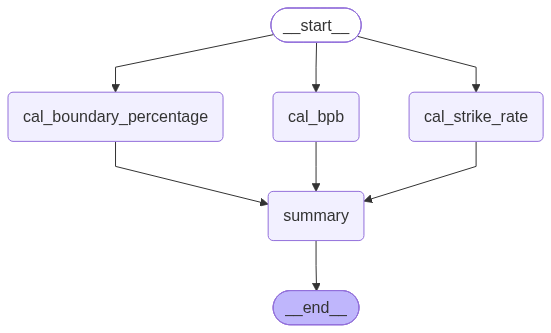

In [27]:
workflow

In [28]:
initial_state = {'runs':120, 'balls':41, 'fours':6, 'sixes':11}
final_state = workflow.invoke(initial_state)

In [30]:
print(final_state['summary'])


Strike Rate : 292.6829268292683

Balls per boundary : 2.411764705882353

Boundary Percentage : 75.0
